# 01 — Tổng quan & Chất lượng dữ liệu Geolife

Mục tiêu notebook:
1. Quy mô dataset: số user, số trajectory, số điểm, phân bố theo user (độ lệch).
2. Kiểm tra định dạng file `.plt`: header, cột hằng số, tính nhất quán giữa cột `days` và `date/time`.
3. Chất lượng giá trị: toạ độ ngoài phạm vi, altitude `-777`, trùng lặp, thứ tự thời gian.
4. Tần suất lấy mẫu (sampling interval), khoảng trống (gap), độ dài/thời lượng trajectory.
5. Chồng lấn thời gian giữa các trajectory của cùng user.

Dữ liệu được đọc thẳng từ các file `.plt` gốc (`EDA/utils.py`) và xử lý trong bộ nhớ, không lưu file trung gian.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from utils import add_kinematics, haversine, load_files, load_labels, load_points, savefig, setup_style, ROOT

setup_style()
pts = load_points()
files = load_files()
labels = load_labels()
pts["traj_key"] = pts["user"].astype(str) + "_" + pts["traj_id"].astype(str)
print(pts.dtypes)
print(f"Bộ nhớ: {pts.memory_usage(deep=True).sum() / 1e9:.2f} GB")
pts.head()

user                 int16
traj_id           category
lat                float64
lon                float64
alt_ft             float64
zero                 int64
days               float64
ts_utc      datetime64[us]
mode              category
traj_key               str
dtype: object
Bộ nhớ: 1.95 GB


,user,traj_id,lat,lon,alt_ft,zero,days,ts_utc,mode,traj_key
0,0,20081023025304,39.9847,116.3184,492.0000,0,"39,744.1202",2008-10-23 02:53:04,NaN,0_20081023025304
1,0,20081023025304,39.9847,116.3184,492.0000,0,"39,744.1203",2008-10-23 02:53:10,NaN,0_20081023025304
2,0,20081023025304,39.9847,116.3184,492.0000,0,"39,744.1203",2008-10-23 02:53:15,NaN,0_20081023025304
3,0,20081023025304,39.9847,116.3184,492.0000,0,"39,744.1204",2008-10-23 02:53:20,NaN,0_20081023025304
4,0,20081023025304,39.9847,116.3183,492.0000,0,"39,744.1204",2008-10-23 02:53:25,NaN,0_20081023025304


## 1. Quy mô dataset

In [2]:
summary = pd.Series({
    "Số user": pts.user.nunique(),
    "Số user có labels.txt": labels.user.nunique(),
    "Số trajectory (.plt)": len(files),
    "Số điểm GPS": len(pts),
    "Điểm/trajectory (median)": files.n_points.median(),
    "Thời gian bắt đầu (UTC)": pts.ts_utc.min(),
    "Thời gian kết thúc (UTC)": pts.ts_utc.max(),
    "Tổng dung lượng .plt (GB)": files.file_bytes.sum() / 1e9,
})
summary.to_frame("giá trị")

,giá trị
Số user,182
Số user có labels.txt,69
Số trajectory (.plt),18670
Số điểm GPS,24876978
Điểm/trajectory (median),506.0000
Thời gian bắt đầu (UTC),2000-01-01 23:12:19
Thời gian kết thúc (UTC),2012-07-27 08:31:20
Tổng dung lượng .plt (GB),1.6671


In [3]:
per_user = (pts.groupby("user")
            .agg(n_points=("lat", "size"), n_traj=("traj_id", "nunique"),
                 first=("ts_utc", "min"), last=("ts_utc", "max"))
            .assign(span_days=lambda d: (d["last"] - d["first"]).dt.days,
                    n_days=pts.groupby("user")["ts_utc"].apply(lambda s: s.dt.date.nunique()))
            .sort_values("n_points", ascending=False))
per_user["share_points_%"] = per_user.n_points / per_user.n_points.sum() * 100
per_user["cum_share_%"] = per_user["share_points_%"].cumsum()
per_user.head(15)

,n_points,n_traj,first,last,span_days,n_days,share_points_%,cum_share_%
user,,,,,,,,
153,2156994,2024,2007-07-21 05:07:08,2012-06-17 16:51:05,1793,1273,8.6706,8.6706
128,1208500,2153,2007-04-14 00:56:28,2011-03-10 08:00:22,1426,909,4.8579,13.5285
41,1057043,557,2009-02-13 03:48:06,2009-07-12 08:35:49,149,141,4.2491,17.7776
17,1026179,391,2008-10-30 09:27:48,2009-07-04 12:08:32,247,198,4.1250,21.9026
163,969100,809,2000-01-01 23:12:19,2012-07-27 08:31:20,4590,552,3.8956,25.7982
68,937876,408,2008-09-14 13:03:08,2009-09-13 12:51:15,363,297,3.7701,29.5683
10,935576,161,2007-08-04 03:30:32,2009-03-21 05:34:53,595,125,3.7608,33.3291
25,629896,757,2008-12-15 00:01:52,2009-07-11 09:16:28,208,189,2.5320,35.8611
167,618649,385,2008-03-01 03:07:56,2009-02-17 02:11:02,352,263,2.4868,38.3480


15 user (8.2%) chiếm 50% số điểm
40 user chiếm 80% số điểm
             count         mean          std     min        25%         50%          75%            max
n_points  182.0000 136,686.6923 265,635.3683 17.0000 3,359.0000 35,181.5000 143,041.5000 2,156,994.0000
n_traj    182.0000     102.5824     250.0636  1.0000     8.0000     27.5000      89.7500     2,153.0000
n_days    182.0000      61.2473     132.7891  1.0000     7.0000     19.5000      63.2500     1,273.0000
span_days 182.0000     187.5220     438.1095  0.0000     9.0000     70.0000     166.2500     4,590.0000


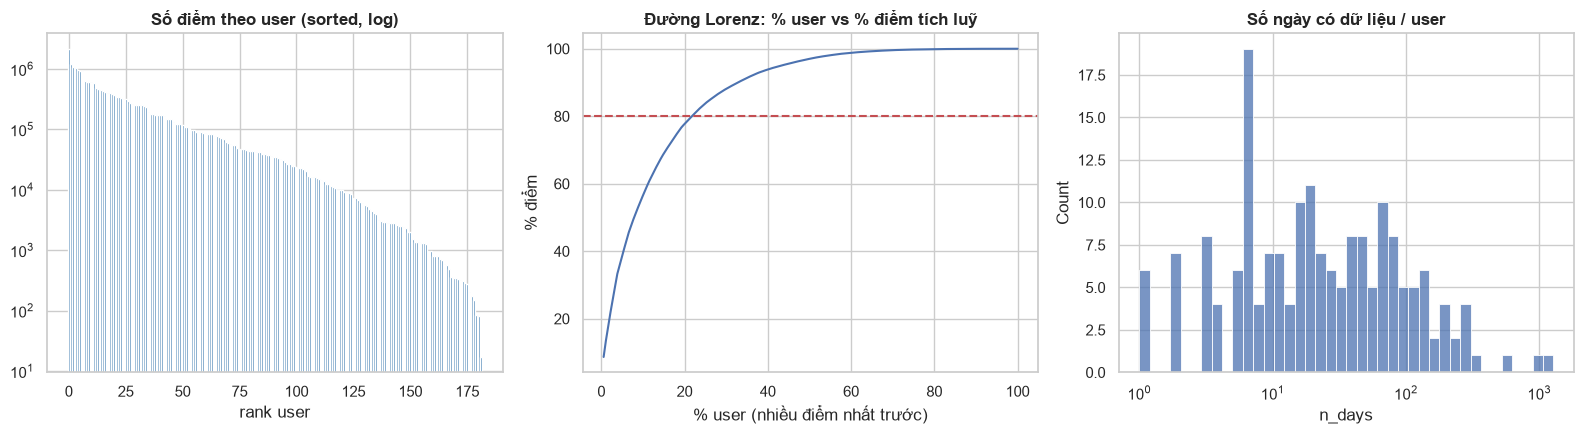

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].bar(range(len(per_user)), per_user.n_points.values, color="steelblue")
axes[0].set_yscale("log"); axes[0].set_title("Số điểm theo user (sorted, log)"); axes[0].set_xlabel("rank user")
axes[1].plot(np.arange(1, len(per_user) + 1) / len(per_user) * 100, per_user["cum_share_%"].values)
axes[1].axhline(80, ls="--", c="r"); axes[1].set_title("Đường Lorenz: % user vs % điểm tích luỹ")
axes[1].set_xlabel("% user (nhiều điểm nhất trước)"); axes[1].set_ylabel("% điểm")
sns.histplot(per_user.n_days, bins=40, ax=axes[2], log_scale=True)
axes[2].set_title("Số ngày có dữ liệu / user")
plt.tight_layout(); savefig("01_user_imbalance")

top_k = (per_user["cum_share_%"] <= 50).sum() + 1
print(f"{top_k} user ({top_k / len(per_user):.1%}) chiếm 50% số điểm")
print(f"{(per_user['cum_share_%'] <= 80).sum() + 1} user chiếm 80% số điểm")
print(per_user[["n_points", "n_traj", "n_days", "span_days"]].describe().T)

**Insight:** dữ liệu rất lệch theo user (vài user "power user" chiếm phần lớn điểm).
→ Khi đánh giá model home/office, cần đánh giá *theo user* (macro), không gộp điểm (micro), nếu không kết quả sẽ bị chi phối bởi vài user.

## 2. Kiểm tra định dạng file `.plt`

In [5]:
raw_dir = ROOT / "data" / "Geolife_Trajectories" / "Data"
sample_files = sorted(raw_dir.glob("*/Trajectory/*.plt"))
headers = {}
for f in sample_files:
    with open(f) as fh:
        h = tuple(next(fh).strip() for _ in range(6))
    headers[h] = headers.get(h, 0) + 1
print(f"Số file: {len(sample_files):,} — số loại header 6 dòng khác nhau: {len(headers)}")
for h, c in headers.items():
    print(c, h)

Số file: 18,670 — số loại header 6 dòng khác nhau: 1
18670 ('Geolife trajectory', 'WGS 84', 'Altitude is in Feet', 'Reserved 3', '0,2,255,My Track,0,0,2,8421376', '0')


In [6]:
print("Giá trị cột thứ 3 (zero):", pts["zero"].value_counts().to_dict())
# Kiểm tra cột days (Excel serial date, gốc 1899-12-30) vs date/time
ts_from_days = pd.Timestamp("1899-12-30") + pd.to_timedelta(pts["days"], unit="D")
diff_s = (ts_from_days - pts["ts_utc"]).dt.total_seconds().abs()
print("Lệch |days - date/time| (giây):")
print(diff_s.describe(percentiles=[.5, .99, .999]))
print("Số điểm lệch > 1s:", (diff_s > 1).sum())

Giá trị cột thứ 3 (zero): {0: 24876978}


Lệch |days - date/time| (giây):


count   24,876,978.0000
mean             0.0000
std              0.0000
min              0.0000
50%              0.0000
99%              0.0000
99.9%            0.0000
max              0.0000
dtype: float64
Số điểm lệch > 1s: 0


**Insight:** cột thứ 3 luôn = 0 và cột `days` trùng với `date+time` (sai khác chỉ do làm tròn) → có thể bỏ 2 cột này, dùng `date+time` làm timestamp chuẩn (UTC theo User Guide).

## 3. Chất lượng giá trị

In [7]:
checks = pd.Series({
    "lat ngoài [-90,90]": (~pts.lat.between(-90, 90)).sum(),
    "lon ngoài [-180,180]": (~pts.lon.between(-180, 180)).sum(),
    "lat = 0 hoặc lon = 0": ((pts.lat == 0) | (pts.lon == 0)).sum(),
    "altitude = -777 (invalid)": (pts.alt_ft == -777).sum(),
    "altitude < -1000 ft": (pts.alt_ft < -1000).sum(),
    "altitude > 30000 ft": (pts.alt_ft > 30000).sum(),
    "năm < 2007": (pts.ts_utc.dt.year < 2007).sum(),
    "năm > 2012": (pts.ts_utc.dt.year > 2012).sum(),
    "NaN lat/lon": pts[["lat", "lon"]].isna().any(axis=1).sum(),
})
checks.to_frame("số điểm").assign(pct=lambda d: d["số điểm"] / len(pts) * 100)

,số điểm,pct
"lat ngoài [-90,90]",1,0.0000
"lon ngoài [-180,180]",0,0.0000
lat = 0 hoặc lon = 0,0,0.0000
altitude = -777 (invalid),55484,0.2230
altitude < -1000 ft,29448,0.1184
altitude > 30000 ft,41617,0.1673
năm < 2007,3,0.0000
năm > 2012,0,0.0000
NaN lat/lon,0,0.0000


In [8]:
# Xem chi tiết các điểm bất thường: lat ngoài phạm vi và năm < 2007
pts.loc[(~pts.lat.between(-90, 90)) | (pts.ts_utc.dt.year < 2007),
        ["user", "traj_id", "lat", "lon", "alt_ft", "ts_utc"]]

,user,traj_id,lat,lon,alt_ft,ts_utc
5067886,20,20110911000506,400.1667,116.2154,0.0000,2011-09-11 03:23:54
22578366,163,20000101231219,39.9890,116.3270,128.9370,2000-01-01 23:12:19
22578367,163,20000101231219,39.9910,116.3270,221.1286,2000-01-01 23:13:21
22578368,163,20000101231219,39.9932,116.3268,217.1916,2000-01-01 23:15:23


In [9]:
# User 163 có điểm năm 2000 → kiểm tra cả trajectory đó (thường là lỗi đồng hồ thiết bị trước khi có GPS fix)
bad_traj = pts.loc[pts.ts_utc.dt.year < 2007, "traj_id"].unique()
pts[pts.traj_id.isin(bad_traj)].groupby("traj_id", observed=True).agg(
    n=("lat", "size"), tmin=("ts_utc", "min"), tmax=("ts_utc", "max"), lat_med=("lat", "median"))

,n,tmin,tmax,lat_med
traj_id,,,,
20000101231219,3,2000-01-01 23:12:19,2000-01-01 23:15:23,39.9910


In [10]:
print("Phân bố năm (UTC):")
print(pts.ts_utc.dt.year.value_counts().sort_index())

Phân bố năm (UTC):
ts_utc
2000           3
2007      291329
2008     8115349
2009    11541481
2010     1416492
2011     2846208
2012      666116
Name: count, dtype: int64


count   24,821,494.0000
mean           157.2466
std            702.1793
min         -9,950.9885
1%             -23.1648
50%             44.9885
99%          3,446.0688
max         32,767.0058
Name: alt_ft, dtype: float64


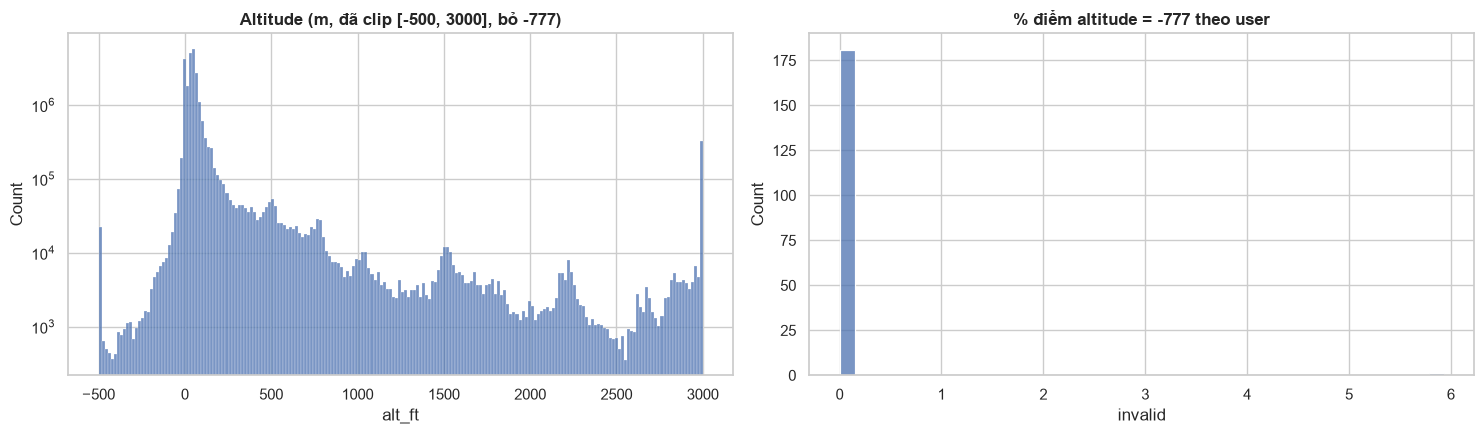

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
alt_m = pts.loc[pts.alt_ft != -777, "alt_ft"] * 0.3048
sns.histplot(alt_m.clip(-500, 3000), bins=200, ax=axes[0])
axes[0].set_title("Altitude (m, đã clip [-500, 3000], bỏ -777)"); axes[0].set_yscale("log")
alt_by_user = pts.assign(invalid=pts.alt_ft == -777).groupby("user").invalid.mean() * 100
sns.histplot(alt_by_user, bins=40, ax=axes[1]); axes[1].set_title("% điểm altitude = -777 theo user")
plt.tight_layout(); savefig("01_altitude")
print(alt_m.describe(percentiles=[.01, .5, .99]))

**Insight:** Bắc Kinh cao ~40–60m so với mực nước biển. Altitude có nhiều giá trị âm/rất lớn và `-777` → altitude **không đáng tin**, không nên dùng làm feature cho stay-point/home-office (chỉ dùng phát hiện máy bay nếu cần).

### 3.1 Trùng lặp & thứ tự thời gian

In [12]:
pts = pts.sort_values(["user", "traj_id", "ts_utc"], kind="stable").reset_index(drop=True)
dup_exact = pts.duplicated(["user", "traj_id", "ts_utc", "lat", "lon"]).sum()
dup_ts_in_traj = pts.duplicated(["user", "traj_id", "ts_utc"]).sum()
dup_ts_user = pts.duplicated(["user", "ts_utc"]).sum()
print(f"Trùng hoàn toàn (user, traj, ts, lat, lon): {dup_exact:,} ({dup_exact / len(pts):.3%})")
print(f"Trùng timestamp trong cùng traj (có thể khác toạ độ): {dup_ts_in_traj:,}")
print(f"Trùng timestamp trong cùng user (khác traj → các file chồng lấn): {dup_ts_user:,} ({dup_ts_user / len(pts):.3%})")

Trùng hoàn toàn (user, traj, ts, lat, lon): 146,914 (0.591%)
Trùng timestamp trong cùng traj (có thể khác toạ độ): 698,900
Trùng timestamp trong cùng user (khác traj → các file chồng lấn): 698,900 (2.809%)


In [13]:
# Các điểm trùng giây cách điểm giữ lại (điểm xuất hiện đầu tiên) bao xa?
first = ~pts.duplicated(["user", "ts_utc"])
grp = (first.cumsum()).to_numpy()  # pts đã sort theo (user, traj, ts) nên mỗi nhóm trùng nằm liền nhau
ref_lat = pts.lat.to_numpy()[first.to_numpy()][grp - 1]
ref_lon = pts.lon.to_numpy()[first.to_numpy()][grp - 1]
dd = haversine(ref_lat, ref_lon, pts.lat.to_numpy(), pts.lon.to_numpy())[~first.to_numpy()]
print("Khoảng cách điểm trùng giây → điểm đầu tiên cùng giây (m):")
print(pd.Series(dd).describe(percentiles=[.5, .9, .95, .99]).round(1))
print(f"% điểm trùng cách < 10 m: {(dd < 10).mean():.1%} | < 50 m: {(dd < 50).mean():.1%}")

Khoảng cách điểm trùng giây → điểm đầu tiên cùng giây (m):
count   698,900.0000
mean         59.1000
std       6,563.5000
min           0.0000
50%           0.5000
90%           2.7000
95%           4.3000
99%           8.5000
max     852,278.9000
dtype: float64
% điểm trùng cách < 10 m: 99.5% | < 50 m: 100.0%


In [14]:
# Thứ tự thời gian trong file gốc: đếm số lần timestamp giảm theo thứ tự dòng
raw_order = load_points(["user", "traj_id", "ts_utc"])
same = (raw_order.traj_id.values[1:] == raw_order.traj_id.values[:-1]) & (raw_order.user.values[1:] == raw_order.user.values[:-1])
backward = (np.diff(raw_order.ts_utc.values.astype("int64")) < 0) & same
print(f"Số lần timestamp đi lùi trong file gốc: {backward.sum():,} "
      f"(ở {raw_order.traj_id.values[1:][backward].astype(str).size and pd.Series(raw_order.traj_id.values[1:][backward]).nunique()} file)")
del raw_order

Số lần timestamp đi lùi trong file gốc: 0 (ở 0 file)


**Insight:** timestamp trong file luôn tăng dần (không cần sort lại thứ tự trong file), hai file khác nhau **của cùng user** không trùng điểm nào,
nhưng có ~2.8% điểm **trùng timestamp trong cùng trajectory** (dt = 0) → phải bỏ trước khi tính tốc độ (chia cho 0).
Các điểm trùng giây gần như trùng vị trí, nên giữ điểm nào cũng không đổi nơi dừng.

### 3.2 File trùng giữa các user khác nhau

Hai file ở hai thư mục user khác nhau được coi là cùng một file khi trùng tên, số điểm, điểm đầu và thời điểm cuối.
Nối các cặp user có chung file thành nhóm (connected components).

In [15]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

fk = (pts.groupby(["user", "traj_id"], observed=True)
      .agg(n=("lat", "size"), lat0=("lat", "first"), lon0=("lon", "first"), t_end=("ts_utc", "max")).reset_index())
fk["dup_id"] = fk.groupby(["traj_id", "n", "lat0", "lon0", "t_end"], observed=True).ngroup()
fk["cross_dup"] = fk.duplicated("dup_id", keep=False)
d = fk[fk.cross_dup]
pairs = d.merge(d, on="dup_id").query("user_x < user_y")
users = np.sort(fk.user.unique()); ix = {u: i for i, u in enumerate(users)}
m = coo_matrix((np.ones(len(pairs)), (pairs.user_x.map(ix), pairs.user_y.map(ix))), shape=(len(users),) * 2)
_, comp = connected_components(m, directed=False)
comp = pd.Series(comp, index=users)
size = comp.map(comp.value_counts())
user_pts = pts.groupby("user").size()
big = comp.index[comp == comp.value_counts().idxmax()]
dup_share = d.groupby("user").n.sum().reindex(users, fill_value=0) / user_pts
print(f"File trùng: {fk.cross_dup.sum():,} file, {d.n.sum():,} điểm ({d.n.sum() / len(pts):.1%} tổng số điểm)")
print(f"Nhóm có > 1 user: {(comp.value_counts() > 1).sum()} nhóm, gồm {(size > 1).sum()} user")
print(f"Nhóm lớn nhất: {len(big)} user, {user_pts[big].sum() / len(pts):.1%} số điểm: {list(big)}")
print(f"User có 100% dữ liệu là bản sao: {list(dup_share.index[dup_share >= 1])}")
print("Cặp user có nhiều file chung nhất:")
print(pairs.groupby(["user_x", "user_y"]).size().sort_values(ascending=False).head(5).to_string())
d[d.dup_id == d.dup_id.iloc[0]][["user", "traj_id", "n", "lat0", "lon0", "t_end"]]

File trùng: 1,679 file, 2,966,117 điểm (11.9% tổng số điểm)
Nhóm có > 1 user: 18 nhóm, gồm 52 user
Nhóm lớn nhất: 15 user, 25.1% số điểm: [56, 78, 82, 101, 109, 110, 112, 115, 126, 128, 140, 153, 156, 163, 167]
User có 100% dữ liệu là bản sao: [57, 59, 70, 88, 94, 108, 109, 124, 127, 150, 156]
Cặp user có nhiều file chung nhất:
user_x  user_y
153     163       225
126     167       145
0       3         129
11      88         59
128     153        55


,user,traj_id,n,lat0,lon0,t_end
42,0,20090330005208,1328,40.0000,116.3264,2009-03-30 16:11:06
610,3,20090330005208,1328,40.0000,116.3264,2009-03-30 16:11:06


**Insight:** khoảng 1/8 dữ liệu là file được chép y hệt sang thư mục của user khác (cùng một thiết bị / chia sẻ dữ liệu trong nhóm).
Không xác định được ai là chủ thật. Nếu chia train/test theo từng user, cùng một trajectory sẽ nằm ở cả hai phía → phải chia theo **nhóm user**.
Nhóm lớn nhất gom các power user, chiếm một phần lớn dữ liệu.

In [16]:
# Tên file = thời điểm bắt đầu? So sánh với timestamp điểm đầu
first_ts = pts.groupby(["user", "traj_id"], observed=True).ts_utc.min().reset_index()
first_ts["name_ts"] = pd.to_datetime(first_ts.traj_id.astype(str), format="%Y%m%d%H%M%S")
first_ts["diff_s"] = (first_ts.ts_utc - first_ts.name_ts).dt.total_seconds()
print(first_ts.diff_s.describe())
print("Tỉ lệ file tên khớp timestamp đầu (|diff|<=1s):", (first_ts.diff_s.abs() <= 1).mean())

count   18,670.0000
mean         0.0000
std          0.0000
min          0.0000
25%          0.0000
50%          0.0000
75%          0.0000
max          0.0000
Name: diff_s, dtype: float64
Tỉ lệ file tên khớp timestamp đầu (|diff|<=1s): 1.0


## 4. Sampling interval, gap & kinematics thô

In [17]:
pts = add_kinematics(pts)
dt = pts.dt_s.dropna()
print(dt.describe(percentiles=[.05, .25, .5, .75, .9, .95, .99, .999]))
bins = [-np.inf, 0, 1, 2, 5, 10, 30, 60, 300, 1800, 3600, np.inf]
lbl = ["<=0", "(0,1]", "(1,2]", "(2,5]", "(5,10]", "(10,30]", "(30,60]", "(1,5]m", "(5,30]m", "(30,60]m", ">1h"]
pd.cut(dt, bins=bins, labels=lbl).value_counts(normalize=True).sort_index().mul(100).round(3).to_frame("% khoảng")

count   24,858,308.0000
mean             7.2666
std            190.8773
min              0.0000
5%               1.0000
25%              1.0000
50%              2.0000
75%              5.0000
90%              5.0000
95%              5.0000
99%             19.0000
99.9%          578.0000
max         93,298.0000
Name: dt_s, dtype: float64


,% khoảng
dt_s,
<=0,2.8120
"(0,1]",30.3400
"(1,2]",31.7890
"(2,5]",31.5270
"(5,10]",2.1460
"(10,30]",0.6470
"(30,60]",0.2550
"(1,5]m",0.3240
"(5,30]m",0.1130


User có median dt > 5s: 39


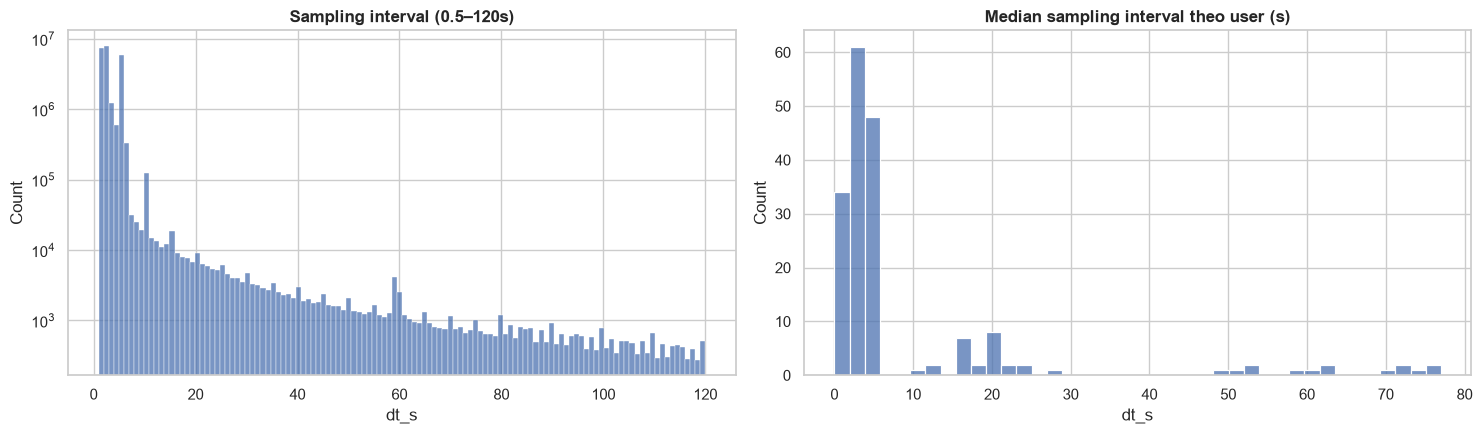

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(dt[dt.between(0.5, 120)], bins=120, ax=axes[0])
axes[0].set_title("Sampling interval (0.5–120s)"); axes[0].set_yscale("log")
med_dt_user = pts.groupby("user").dt_s.median()
sns.histplot(med_dt_user, bins=40, ax=axes[1]); axes[1].set_title("Median sampling interval theo user (s)")
plt.tight_layout(); savefig("01_sampling_interval")
print("User có median dt > 5s:", (med_dt_user > 5).sum())

In [19]:
# Sampling rate thay đổi theo thời gian (thiết bị/cấu hình khác nhau qua các năm)
pts["year"] = pts.ts_utc.dt.year
pts.groupby("year").dt_s.agg(["median", "mean", lambda s: (s <= 5).mean()]).rename(columns={"<lambda_0>": "share_dt<=5s"})

,median,mean,share_dt<=5s
year,,,
2000,92.0000,92.0000,0.0000
2007,2.0000,30.4494,0.7305
2008,2.0000,7.3081,0.9664
2009,2.0000,7.7608,0.9666
2010,2.0000,5.8241,0.9048
2011,1.0000,3.6014,0.9926
2012,2.0000,6.8184,0.9931


**Insight:** User Guide nói ~91.5% trajectory là dense (1–5s). Có nhóm user/năm ghi thưa hơn → ngưỡng stay-point theo *số điểm* sẽ không ổn định; nên dùng ngưỡng theo **thời gian + khoảng cách** (ví dụ 200m/20–30 phút) thay vì số điểm.

In [20]:
# Gap lớn bên trong một trajectory
gap_thr = [60, 300, 1800, 3600, 6 * 3600]
for g in gap_thr:
    n = (pts.dt_s > g).sum()
    print(f"gap > {g:>6}s: {n:>8,} lần, ở {pts.loc[pts.dt_s > g, 'traj_key'].nunique():>6,} trajectory")

gap >     60s:  120,412 lần, ở 14,158 trajectory
gap >    300s:   39,810 lần, ở  9,513 trajectory
gap >   1800s:   11,841 lần, ở  5,537 trajectory
gap >   3600s:    7,342 lần, ở  4,274 trajectory
gap >  21600s:       50 lần, ở     49 trajectory


## 5. Trajectory-level stats

In [21]:
traj = (pts.groupby("traj_key", observed=True)
        .agg(user=("user", "first"), n=("lat", "size"), start=("ts_utc", "min"), end=("ts_utc", "max"),
             length_km=("dist_m", lambda s: s.sum() / 1000), max_gap_s=("dt_s", "max"),
             med_dt=("dt_s", "median"), lat0=("lat", "first"), lon0=("lon", "first"),
             lat1=("lat", "last"), lon1=("lon", "last")))
traj["duration_min"] = (traj.end - traj.start).dt.total_seconds() / 60
traj["od_km"] = haversine(traj.lat0, traj.lon0, traj.lat1, traj.lon1) / 1000
traj["avg_speed_kmh"] = traj.length_km / (traj.duration_min / 60).replace(0, np.nan)
traj[["n", "duration_min", "length_km", "od_km", "avg_speed_kmh", "max_gap_s", "med_dt"]].describe(
    percentiles=[.05, .25, .5, .75, .95, .99]).T

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
n,"18,670.0000","1,332.4573","2,821.5138",3.0000,28.0000,201.0000,506.0000,"1,367.0000","5,195.8500","11,624.6400","92,645.0000"
duration_min,"18,670.0000",161.2537,259.9923,0.0333,3.7333,16.8333,42.1333,192.4292,715.8675,"1,039.5142","5,807.1833"
length_km,"18,670.0000",69.2378,"4,047.1517",0.0000,0.4782,2.7844,10.0818,22.4508,94.2733,647.0660,"551,558.0341"
od_km,"18,670.0000",21.8147,192.1780,0.0000,0.0592,0.6239,2.3665,9.4035,26.2633,467.4908,"9,215.3157"
avg_speed_kmh,"18,670.0000",19.6830,348.4289,0.0000,1.4612,5.1254,10.2741,20.5339,48.2381,92.4747,"47,304.5604"
max_gap_s,"18,670.0000","2,925.1285","5,278.9209",1.0000,5.0000,64.0000,325.0000,"2,903.7500","15,634.7500","20,689.8600","93,298.0000"
med_dt,"18,670.0000",5.9582,110.6521,0.0000,1.0000,2.0000,2.0000,5.0000,15.0000,53.5000,"14,465.5000"


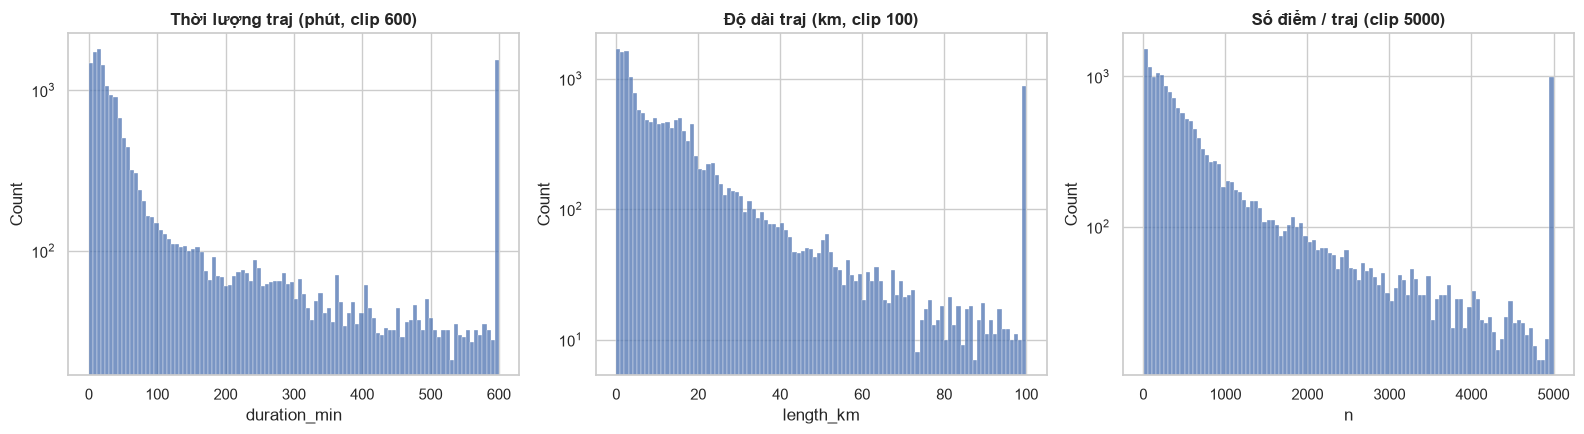

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(traj.duration_min.clip(upper=600), bins=100, ax=axes[0]); axes[0].set_title("Thời lượng traj (phút, clip 600)")
sns.histplot(traj.length_km.clip(upper=100), bins=100, ax=axes[1]); axes[1].set_title("Độ dài traj (km, clip 100)")
sns.histplot(traj.n.clip(upper=5000), bins=100, ax=axes[2]); axes[2].set_title("Số điểm / traj (clip 5000)")
for a in axes: a.set_yscale("log")
plt.tight_layout(); savefig("01_traj_stats")

In [23]:
print("Trajectory rất ngắn (<10 điểm):", (traj.n < 10).sum())
print("Trajectory < 1 phút:", (traj.duration_min < 1).sum())
print("Trajectory > 24h:", (traj.duration_min > 24 * 60).sum())
print("Trajectory có max_gap > 1h:", (traj.max_gap_s > 3600).sum())
print("Trajectory 'khép kín' (điểm đầu-cuối < 200m) & dài > 1km:", ((traj.od_km < 0.2) & (traj.length_km > 1)).sum())

Trajectory rất ngắn (<10 điểm): 306
Trajectory < 1 phút: 330
Trajectory > 24h: 74
Trajectory có max_gap > 1h: 4274
Trajectory 'khép kín' (điểm đầu-cuối < 200m) & dài > 1km: 1476


## 6. Chồng lấn thời gian giữa các trajectory của cùng user

In [24]:
t = traj.sort_values(["user", "start"])
t["prev_end"] = t.groupby("user").end.shift()
t["overlap_s"] = (t.prev_end - t.start).dt.total_seconds()
ov = t[t.overlap_s > 0]
print(f"Số cặp traj liên tiếp chồng lấn thời gian: {len(ov):,} / {len(t):,} ({len(ov) / len(t):.2%}), ở {ov.user.nunique()} user")
print(ov.overlap_s.describe())

Số cặp traj liên tiếp chồng lấn thời gian: 0 / 18,670 (0.00%), ở 0 user
count   0.0000
mean       NaN
std        NaN
min        NaN
25%        NaN
50%        NaN
75%        NaN
max        NaN
Name: overlap_s, dtype: float64


count   18,488.0000
mean        41.7056
std        666.5378
min          0.0003
25%          6.4860
50%         11.1839
75%         16.4826
90%         37.3215
95%         70.8849
max     63,779.0981
Name: gap_between_h, dtype: float64
Gap 4–24h mà jump < 0.5km: 0.6002026855839878


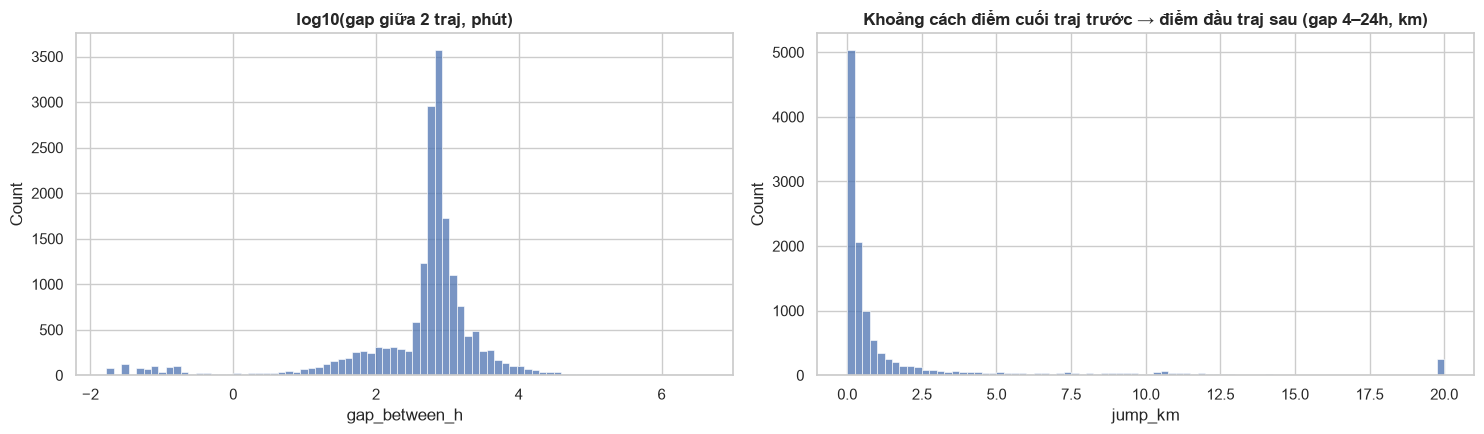

In [25]:
# Khoảng nghỉ giữa 2 trajectory liên tiếp (device tắt / không ghi) — quan trọng cho home detection
t["gap_between_h"] = -t.overlap_s / 3600
t["jump_km"] = haversine(t.groupby("user").lat1.shift(), t.groupby("user").lon1.shift(), t.lat0, t.lon0) / 1000
g = t.dropna(subset=["gap_between_h"])
g = g[g.gap_between_h > 0]
print(g.gap_between_h.describe(percentiles=[.25, .5, .75, .9, .95]))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(np.log10(g.gap_between_h * 60), bins=80, ax=ax[0]); ax[0].set_title("log10(gap giữa 2 traj, phút)")
sns.histplot(g.loc[g.gap_between_h.between(4, 24), "jump_km"].clip(upper=20), bins=80, ax=ax[1])
ax[1].set_title("Khoảng cách điểm cuối traj trước → điểm đầu traj sau (gap 4–24h, km)")
plt.tight_layout(); savefig("01_between_traj_gap")
print("Gap 4–24h mà jump < 0.5km:", (g.loc[g.gap_between_h.between(4, 24), "jump_km"] < 0.5).mean())

**Insight quan trọng cho bài toán home/office:** người dùng thường **tắt ghi khi đến nơi** (nhà/công ty).
Do đó thời gian ở nhà/công ty phần lớn *không có điểm GPS* mà nằm trong **khoảng trống giữa 2 trajectory**.
Nếu khoảng trống dài (vd. qua đêm) và điểm cuối trước ≈ điểm đầu sau, đó là ứng viên stay rất mạnh → stay-point detection
nên xét cả "gap stay" (nối điểm cuối/đầu), không chỉ cụm điểm dày đặc bên trong trajectory.